# Feature engineering: claims frequency (freMTPL2)

**Goal:** turn the cleaned policy table into model inputs, one decision at a time, each justified by evidence found in the **training set only**.

**Two kinds of transformation**

| Kind | Examples | Rule |
|---|---|---|
| Row-wise, fixed rules | bands with chosen edges, `log`, 0/1 flags | safe anywhere: each row is transformed alone, nothing is learned from the data |
| Learned from data | scaling (mean/std), one-hot levels, merging rare levels | must be fitted on a **training part only** (inside each CV fold, through a Pipeline) |

**Never model inputs:** `IDpol`, `Group`, `Fold`, `ClaimNb`, `Exposure` (it is the weight/offset, not a feature), `Area` (it is binned `Density`), and every target-side column (`Frequency`, `HasClaim`, `TotalClaimAmount`, `SevRows`, `AvgSeverity`, `PurePremium`, `MissingSev`, `logExposure`).

**Plan:** 1. bands and logs, 2. check the numeric transformations (bonus-malus gets special attention), 3. categorical features, 4. learned preprocessing in a pipeline, 5. compare with the saved module `src/features.py`.

In [13]:
# Cell 1: setup and training data
# The test set is never loaded in this notebook, so no decision below can be influenced by it.
# (Magics must stay alone on their line: no comments after them.)
%load_ext autoreload
%autoreload 2

import sys; sys.path.append("..")      # lets the notebook import our project code from src/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.evaluation import load_train    # training policies + the frozen Fold column

train = load_train()
print(train.shape)    # your run: (541432, 23) = 21 cleaned columns + Group + Fold
train.head(3)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(541432, 23)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,...,TotalClaimAmount,Frequency,HasClaim,PurePremium,AvgSeverity,logDensity,logExposure,MissingSev,Group,Fold
0,1,1,0.10,5,0,55,50,B12,Regular,D,...,0.0,10.000000,1,0.0,NaN,7.104144,-2.302585,True,0,0
1,3,1,0.77,5,0,55,50,B12,Regular,D,...,0.0,1.298701,1,0.0,NaN,7.104144,-0.261365,True,0,0
2,5,1,0.75,6,2,52,50,B12,Diesel,B,...,0.0,1.333333,1,0.0,NaN,3.988984,-0.287682,True,1,3


## Helper: are the levels of a feature populated and sensible?
For any grouping column we want policies, claims, exposure and **frequency = claims / exposure** (sum over sum, never the mean of row ratios). Levels with fewer than 100 claims are flagged as "thin": their frequency is mostly noise (a frequency estimated from `n` claims has a relative error of about `1/sqrt(n)`).

In [14]:
# Cell 2: helper used by every check below
def check_levels(d, col):
    """Policies, claims, exposure and frequency per level of `col`."""
    t = d.groupby(col, observed=True).agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
    t["exposure_share"] = (t["exposure"] / t["exposure"].sum()).round(4)
    t["freq"] = (t["claims"] / t["exposure"]).round(4)           # sum/sum
    t["thin"] = np.where(t["claims"] < 100, "<100 claims", "")
    return t

## Decisions taken from the EDA (relativity = frequency / overall frequency)

| Raw column | What the EDA showed | Decision |
|---|---|---|
| `DrivAge` | U-shape: 2.2x at 18-21, 1.5x at 22-25, lowest at 31-40 (0.89x), small bump at 41-50 | 8 bands: a straight line cannot follow a U-shape |
| `VehAge` | age 0 is 3.1x; ages 1-15 near 0.85-0.98; 16+ is 0.64x | 7 bands, age 0 alone |
| `BonusMalus` | rises from 0.80x at 50 to 5.2x at 151+, but irregular | investigated in Step 2, ends up as 4 features |
| `Density` | smooth rise, 0.82x to 1.31x | `log(Density)`; `Area` is dropped |
| `VehGas`, `VehBrand`, `Region`, `VehPower` | see EDA; `VehPower` has no clean trend; `Region` has thin levels | categories, one-hot (Step 3) |

## Step 1: banded features and log transforms

In [15]:
# Cell 3: Step 1a, bands for driver age and vehicle age
# pd.cut intervals are RIGHT-closed: (17, 21] means ages 18..21.
# The first edge must sit below the minimum value, otherwise that value falls outside every band.
DRIVAGE_EDGES  = [17, 21, 25, 30, 40, 50, 60, 70, 100]
DRIVAGE_LABELS = ["18-21", "22-25", "26-30", "31-40", "41-50", "51-60", "61-70", "71-100"]
VEHAGE_EDGES   = [-1, 0, 1, 2, 5, 10, 15, 100]
VEHAGE_LABELS  = ["00", "01", "02", "03-05", "06-10", "11-15", "16+"]   # zero-padded so they sort in natural order

def band(s, edges, labels):
    """Cut a numeric column into labelled bands. Fails loudly instead of silently creating a 'nan' level."""
    b = pd.cut(s, edges, labels=labels)
    assert b.notna().all(), f"{s.name}: values outside the band edges"
    return b.astype(str)

bands = pd.DataFrame({
    "DrivAgeBand": band(train["DrivAge"], DRIVAGE_EDGES, DRIVAGE_LABELS),
    "VehAgeBand":  band(train["VehAge"], VEHAGE_EDGES, VEHAGE_LABELS),
})
chk = bands.join(train[["IDpol", "ClaimNb", "Exposure"]])

# What to look at: every band is populated (no 'thin' flag), the policies add up to the training size,
# and the frequencies reproduce the EDA shape.

print(check_levels(chk, "DrivAgeBand"), "\n")
print(check_levels(chk, "VehAgeBand"))
assert len(bands) == len(train) and bands["DrivAgeBand"].nunique() == 8 and bands["VehAgeBand"].nunique() == 7

             policies      exposure  claims  exposure_share    freq thin
DrivAgeBand                                                             
18-21            9142   3565.384440     804          0.0125  0.2255     
22-25           22066   9411.152553    1477          0.0329  0.1569     
26-30           52390  23229.595260    2464          0.0813  0.1061     
31-40          135715  66907.129953    6023          0.2341  0.0900     
41-50          131719  70085.344768    7270          0.2452  0.1037     
51-60          107984  60533.394106    5826          0.2118  0.0962     
61-70           50919  30533.534604    2853          0.1068  0.0934     
71-100          31497  21529.168397    2115          0.0753  0.0982      

            policies      exposure  claims  exposure_share    freq thin
VehAgeBand                                                             
00             45992  13195.948255    4106          0.0462  0.3112     
01             57020  26177.962427    2331          

In [16]:
# Cell 4: Step 1b, log transforms and skewness
# Density and bonus-malus effects are RELATIVE (100 -> 200 inhabitants/km2 matters like 10000 -> 20000),
# and a log removes the extreme right tail.
log_density = np.log(train["Density"])            # Density >= 1, so no log(0)
log_bm = np.log(train["BonusMalus"])              # BonusMalus >= 50

print("skew Density    :", round(train["Density"].skew(), 2), "->", round(log_density.skew(), 2))        # your run: 4.65 -> 0.03
print("skew BonusMalus :", round(train["BonusMalus"].skew(), 2), "->", round(log_bm.skew(), 2))         # your run: 1.73 -> 1.36

# BonusMalus stays skewed because most exposure sits exactly at the minimum value 50: a spike cannot be flattened by a log.
share50 = train.loc[train["BonusMalus"] == 50, "Exposure"].sum() / train["Exposure"].sum()
print("exposure share at BonusMalus = 50:", round(share50, 3))                                          # your run: 0.629
# Skewness is not the right test for a GLM anyway. What matters is the SHAPE of the effect: Step 2.

skew Density    : 4.65 -> 0.03
skew BonusMalus : 1.73 -> 1.36
exposure share at BonusMalus = 50: 0.629


## Step 2: is the log-linear shape adequate?

A GLM with `log(x)` as a feature assumes `log(frequency) = a + slope * log(x)`: a straight line on the log scale (a power law). We test it by cutting `x` into fine bins and measuring how far each bin sits from the fitted line **in standard errors**. The log-frequency in a bin with `n` claims has a standard error of about `1/sqrt(n)`, so `gap_in_se = gap * sqrt(n)`. As a rule of thumb, |gap_in_se| above 3 is a real deviation.

Density: slope = 0.083  (doubling Density multiplies frequency by 1.06)
                 exposure  claims      x  log_freq   line    gap  gap_in_se  \
Density                                                                       
(0, 25]         22714.121    1746  2.688    -2.566 -2.565 -0.001     -0.025   
(25, 50]        27999.471    2368  3.608    -2.470 -2.489  0.019      0.913   
(50, 100]       33167.288    2933  4.275    -2.426 -2.434  0.008      0.440   
(100, 200]      35452.621    3266  4.948    -2.385 -2.378 -0.007     -0.384   
(200, 500]      47730.984    4629  5.753    -2.333 -2.311 -0.022     -1.492   
(500, 1000]     29349.283    3159  6.562    -2.229 -2.244  0.015      0.859   
(1000, 2000]    32212.451    3572  7.231    -2.199 -2.189 -0.010     -0.615   
(2000, 5000]    39444.043    4776  8.124    -2.111 -2.115  0.004      0.258   
(5000, 10000]   11203.723    1470  8.902    -2.031 -2.051  0.020      0.751   
(10000, 30000]   6520.720     913  9.949    -1.966 -1.964 -

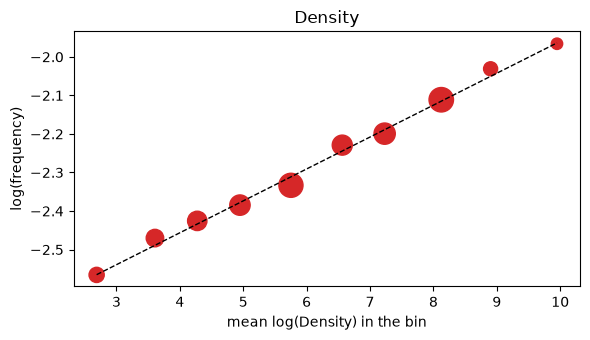

BonusMalus: slope = 1.466  (doubling BonusMalus multiplies frequency by 2.76)
              exposure  claims      x  log_freq   line    gap  gap_in_se  \
BonusMalus                                                                 
(49, 50]    179668.673   14398  3.912    -2.524 -2.517 -0.007     -0.788   
(50, 55]     19462.503    1627  3.967    -2.482 -2.437 -0.044     -1.787   
(55, 60]     18639.727    1993  4.065    -2.236 -2.293  0.058      2.579   
(60, 65]     12170.039    1940  4.148    -1.836 -2.171  0.335     14.746   
(65, 70]      8938.170    1020  4.218    -2.171 -2.069 -0.102     -3.254   
(70, 80]     21202.209    2707  4.327    -2.058 -1.910 -0.149     -7.738   
(80, 90]     12172.741    1712  4.469    -1.962 -1.701 -0.260    -10.762   
(90, 100]    10672.426    2373  4.581    -1.504 -1.537  0.034      1.649   
(100, 125]    2568.264     932  4.738    -1.014 -1.307  0.293      8.958   
(125, 150]     216.682      86  4.935    -0.924 -1.017  0.093      0.862   
(150, 350]

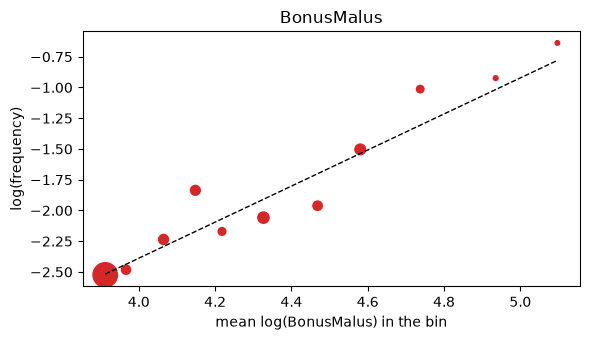

In [17]:
# Cell 5: Step 2a, the straight-line test
def loglinear_check(d, col, edges, title, min_claims=100):
    """Is the effect of log(col) a straight line on the log-frequency scale?"""
    b = pd.cut(d[col], edges)
    g = d.groupby(b, observed=True).agg(
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
        x=(col, lambda s: np.log(s).mean()),           # mean of log(col) inside the bin
    )
    g["log_freq"] = np.log(g["claims"] / g["exposure"])
    ok = g["claims"] >= min_claims                      # thin bins are shown but not used for the fit
    assert ok.sum() >= 3, f"need at least 3 bins with >= {min_claims} claims"
    # weights sqrt(claims) = 1/standard error, so well-measured bins pull the line harder
    slope, intercept = np.polyfit(g.loc[ok, "x"], g.loc[ok, "log_freq"], 1, w=np.sqrt(g.loc[ok, "claims"]))
    g["line"] = intercept + slope * g["x"]
    g["gap"] = g["log_freq"] - g["line"]
    g["gap_in_se"] = g["gap"] * np.sqrt(g["claims"])
    g["thin"] = np.where(ok, "", f"<{min_claims} claims")

    print(f"{title}: slope = {slope:.3f}  (doubling {col} multiplies frequency by {2**slope:.2f})")
    print(g[["exposure", "claims", "x", "log_freq", "line", "gap", "gap_in_se", "thin"]].round(3), "\n")

    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.scatter(g["x"], g["log_freq"], s=g["claims"] / g["claims"].max() * 300 + 10, color="tab:red")   # point size ~ claims
    xs = np.linspace(g["x"].min(), g["x"].max(), 50)
    ax.plot(xs, intercept + slope * xs, "k--", lw=1)
    ax.set_xlabel(f"mean log({col}) in the bin"); ax.set_ylabel("log(frequency)"); ax.set_title(title)
    plt.tight_layout(); plt.show()

# Density: your run gave slope 0.083 and every gap within +-1.5 standard errors -> log(Density) is adequate.
loglinear_check(train, "Density", [0, 25, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 30000], "Density")

# BonusMalus: your run gave gaps of +14.7 (bin 60-65), -10.8 (80-90), +9.0 (100-125) -> NOT a straight line.
loglinear_check(train, "BonusMalus", [49, 50, 55, 60, 65, 70, 80, 90, 100, 125, 150, 350], "BonusMalus")

In [18]:
# Step 2b, look at the EXACT bonus-malus values
# The bumps suggest that specific values matter, so we stop binning and look at each value.
bm = train.groupby("BonusMalus").agg(policies=("IDpol", "size"), exposure=("Exposure", "sum"), claims=("ClaimNb", "sum"))
bm["exposure_share"] = (bm["exposure"] / bm["exposure"].sum()).round(4)
bm["freq"] = (bm["claims"] / bm["exposure"]).round(4)
bm["rel_se"] = (1 / np.sqrt(bm["claims"].clip(lower=1))).round(3)      # relative standard error of the frequency

print(bm.loc[bm["exposure_share"] >= 0.002].to_string())               # values with at least 0.2% of exposure
print("values with < 0.2% of exposure:", (bm["exposure_share"] < 0.002).sum(), "of", len(bm))


            policies       exposure  claims  exposure_share    freq  rel_se
BonusMalus                                                                 
50            306711  179668.673035   14398          0.6287  0.0801   0.008
51             12722    6691.232353     425          0.0234  0.0635   0.049
52              3778    2138.381464     242          0.0075  0.1132   0.064
53              2738    1323.467126     156          0.0046  0.1179   0.080
54             13747    6852.099598     479          0.0240  0.0699   0.046
55              4479    2457.322583     325          0.0086  0.1323   0.055
56              2703    1398.592157     207          0.0049  0.1480   0.070
57             14257    7032.889488     546          0.0246  0.0776   0.043
58              4766    2558.419698     497          0.0090  0.1943   0.045
59              2230    1162.925801     137          0.0041  0.1178   0.085
60             13896    6486.899906     606          0.0227  0.0934   0.041
61          

In [19]:
# Cell 7: Step 2c, build the ladder from the rule and test the explanation
def ladder(start=100, floor=50):
    """Claim-free-year ladder: -5% per year, truncated, never below the floor. Integer arithmetic avoids float surprises."""
    vals, v = [start], start
    while v > floor:
        v = max(floor, v * 95 // 100)
        vals.append(v)
    return vals

LADDER = ladder()
print(LADDER)
assert LADDER == [100, 95, 90, 85, 80, 76, 72, 68, 64, 60, 57, 54, 51, 50]

# 1) on-ladder vs off-ladder: if off-ladder means "recent claim", its frequency must be clearly higher
train["on_ladder"] = train["BonusMalus"].isin(LADDER)
s = train.groupby("on_ladder").agg(policies=("IDpol", "size"), exposure=("Exposure", "sum"), claims=("ClaimNb", "sum"))
s["exposure_share"] = (s["exposure"] / s["exposure"].sum()).round(4)
s["freq"] = (s["claims"] / s["exposure"]).round(4)
print(s, "\n")          # your run: off-ladder 8.9% of exposure, frequency 0.2135 vs 0.0899 on the ladder (2.4x)

# 2) do the rungs 51..95 follow a straight line? BM = 50 and BM = 100 are excluded from the fit
g = train[train["on_ladder"]].groupby("BonusMalus").agg(exposure=("Exposure", "sum"), claims=("ClaimNb", "sum"))
g["x"] = np.log(g.index.to_numpy())
g["log_freq"] = np.log(g["claims"] / g["exposure"])
g["freq"] = (g["claims"] / g["exposure"]).round(4)

rungs = [v for v in LADDER if v not in (50, 100) and v in g.index]
g2 = g.loc[rungs]
slope2, intercept2 = np.polyfit(g2["x"], g2["log_freq"], 1, w=np.sqrt(g2["claims"]))
g["line"] = np.exp(intercept2 + slope2 * g["x"])
g["observed/line"] = (g["freq"] / g["line"]).round(2)
g["gap_in_se"] = ((g["log_freq"] - np.log(g["line"])) * np.sqrt(g["claims"])).round(2)
print(f"rungs only (50 and 100 excluded from the fit): slope = {slope2:.3f}")
print(g[["claims", "freq", "observed/line", "gap_in_se"]])


[100, 95, 90, 85, 80, 76, 72, 68, 64, 60, 57, 54, 51, 50]
           policies       exposure  claims  exposure_share    freq
on_ladder                                                         
False         51012   25471.329286    5437          0.0891  0.2135
True         490420  260323.374795   23395          0.9109  0.0899 

rungs only (50 and 100 excluded from the fit): slope = 1.386
            claims    freq  observed/line  gap_in_se
BonusMalus                                          
50           14398  0.0801           1.28      29.39
51             425  0.0635           0.98      -0.31
54             479  0.0699           1.00       0.04
57             546  0.0776           1.03       0.74
60             606  0.0934           1.16       3.59
64             545  0.0819           0.93      -1.75
68             580  0.0887           0.92      -1.92
72             645  0.1005           0.97      -0.87
76             666  0.1057           0.94      -1.49
80             721  0.1215  

In [20]:
# Cell 8: Step 2d, the final bonus-malus features
# Four features describe the structure:
#   logBonusMalus : the smooth trend along the ladder
#   bm_is_50      : the floor value (63% of exposure) gets its own level
#   bm_is_100     : the neutral starting value gets its own level
#   bm_off_ladder : not a claim-free rung -> likely a recent claim (a multiplicative uplift)
# All are fixed rules on the number itself: nothing is learned from the data, nothing leaks.
def bonus_malus_features(bm):
    return pd.DataFrame({
        "logBonusMalus": np.log(bm),
        "bm_is_50":      (bm == 50).astype(int),
        "bm_is_100":     (bm == 100).astype(int),
        "bm_off_ladder": (~bm.isin(LADDER)).astype(int),
    }, index=bm.index)

f = bonus_malus_features(train["BonusMalus"])
counts = f[["bm_is_50", "bm_is_100", "bm_off_ladder"]].sum().to_dict()
print(counts)
# Regression test with the counts verified in the exact-values table: 306,711 | 15,601 | 51,012
assert counts == {"bm_is_50": 306711, "bm_is_100": 15601, "bm_off_ladder": 51012}
assert ((f["bm_is_50"] + f["bm_is_100"] + f["bm_off_ladder"]) <= 1).all()     # the three flags never overlap

{'bm_is_50': 306711, 'bm_is_100': 15601, 'bm_off_ladder': 51012}


## Step 3: categorical features
`VehGas` (2 levels), `VehBrand` (11), `Region` (21) and `VehPower` (12 values, treated as categories because the EDA showed no clean trend).

* **One-hot, not numeric codes.** Numbering levels (B1=1, B2=2...) would make the GLM fit one slope across arbitrary codes. One-hot gives every level its own 0/1 column, hence its own factor.
* **Thin levels** (e.g. Franche-Comte, 45 claims) get noisy coefficients. Two defenses: merge rare levels into one "infrequent" column (`min_frequency`) and the ridge penalty of the GLM.

In [21]:
# Cell 9: Step 3, levels, thin levels, and what one-hot encoding produces
from sklearn.preprocessing import OneHotEncoder

CATS = ["VehGas", "VehBrand", "Region", "VehPower"]
X_cat = train[CATS].astype(str)

for c in CATS:
    t = check_levels(train, c)
    print(f"{c}: {len(t)} levels | thin (<100 claims): {list(t.index[t['thin'] != ''])}")
# Your run: only Franche-Comte (Region) and 14 (VehPower) are thin.

# min_frequency as a FRACTION of the rows: 0.0037 of 541k is about 2000 policies, i.e. about 100 claims at a 5% claim rate
enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.0037)
M = enc.fit_transform(X_cat)      # here fitted on all of train only to SEE what it does; in CV it is fitted per fold (Step 4)
names = enc.get_feature_names_out()
print("\nmatrix:", M.shape, "| sparse:", hasattr(M, "nnz"))        # your earlier run with the equivalent count threshold of 2000: (541432, 45)
print("merged into 'infrequent':", {c: list(v) for c, v in zip(CATS, enc.infrequent_categories_) if v is not None})
# your run: Region -> Alsace, Franche-Comte ; VehPower -> 14 (a single level is only renamed)

assert (M.getnnz(axis=1) == len(CATS)).all()      # every row has exactly one 1 per variable
print("row 0:", train.loc[0, CATS].to_dict())
print("active columns:", [names[j] for j in M[0].nonzero()[1]])

VehGas: 2 levels | thin (<100 claims): []
VehBrand: 11 levels | thin (<100 claims): []
Region: 21 levels | thin (<100 claims): ['Franche-Comte']
VehPower: 12 levels | thin (<100 claims): [14]

matrix: (541432, 45) | sparse: True
merged into 'infrequent': {'Region': ['Alsace', 'Franche-Comte'], 'VehPower': ['14']}
row 0: {'VehGas': 'Regular', 'VehBrand': 'B12', 'Region': 'Rhone-Alpes', 'VehPower': 5}
active columns: ['VehGas_Regular', 'VehBrand_B12', 'Region_Rhone-Alpes', 'VehPower_5']


## Step 4: learned preprocessing inside a pipeline
Everything above used fixed rules. Now the parts that **learn from data**:

| Component | What it learns |
|---|---|
| `StandardScaler` on `logBonusMalus`, `logDensity` | mean and standard deviation |
| `OneHotEncoder` | the list of levels and which ones are infrequent |

Scaling does not change what an unpenalized GLM predicts, but our GLM has a ridge penalty that treats all coefficients equally, so numeric features should be on the same scale. The three 0/1 flags pass through unchanged (their coefficients stay readable).

In [22]:
# Cell 10: Step 4, the final feature function and the preprocessor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

NUM   = ["logBonusMalus", "logDensity"]
FLAGS = ["bm_is_50", "bm_is_100", "bm_off_ladder"]
CAT   = ["DrivAgeBand", "VehAgeBand", "VehGas", "VehBrand", "Region", "VehPower"]

def add_features(d):
    """All row-wise features (fixed rules). Never includes Area, IDs, targets or Exposure."""
    bm = d["BonusMalus"]
    return pd.DataFrame({
        "DrivAgeBand":   band(d["DrivAge"], DRIVAGE_EDGES, DRIVAGE_LABELS),
        "VehAgeBand":    band(d["VehAge"], VEHAGE_EDGES, VEHAGE_LABELS),
        "logBonusMalus": np.log(bm),
        "bm_is_50":      (bm == 50).astype(int),
        "bm_is_100":     (bm == 100).astype(int),
        "bm_off_ladder": (~bm.isin(LADDER)).astype(int),
        "logDensity":    np.log(d["Density"]),
        "VehGas":        d["VehGas"],
        "VehBrand":      d["VehBrand"],
        "Region":        d["Region"],
        "VehPower":      d["VehPower"].astype(str),      # treated as a category
    }, index=d.index)[NUM + FLAGS + CAT]

def make_preprocessor(min_frequency=0.0037):
    """The learned parts. Always fit on a TRAINING part only."""
    return ColumnTransformer([
        ("num",  StandardScaler(), NUM),                 # learns mean/std
        ("flag", "passthrough", FLAGS),                  # 0/1 flags unchanged
        ("cat",  OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency), CAT),
    ])

# Demonstration with fold 0 as the validation part
tr, va = train[train["Fold"] != 0], train[train["Fold"] == 0]
pre = make_preprocessor()
X_tr = pre.fit_transform(add_features(tr))     # LEARNS from the training part only
X_va = pre.transform(add_features(va))         # only APPLIES what was learned
assert X_tr.shape[1] == X_va.shape[1]
print("train part:", X_tr.shape, "| validation part:", X_va.shape)       # your run: (432904, 65) and (108528, 65)

def dense(M): return M.toarray() if hasattr(M, "toarray") else M
a, b = dense(X_tr[:, :2]), dense(X_va[:, :2])
print("numeric, train part     : mean", a.mean(0).round(4), "std", a.std(0).round(4))     # exactly 0 and 1
print("numeric, validation part: mean", b.mean(0).round(4), "std", b.std(0).round(4))     # close but NOT exact: only train statistics were used
sc = pre.named_transformers_["num"]
print("learned by the scaler: mean", sc.mean_.round(3), "std", np.sqrt(sc.var_).round(3))  # your run: [4.063 5.983] and [0.225 1.869]

inf = pre.named_transformers_["cat"].infrequent_categories_
print("merged as infrequent in this fold:", {c: list(v) for c, v in zip(CAT, inf) if v is not None})

train part: (432904, 65) | validation part: (108528, 65)
numeric, train part     : mean [ 0. -0.] std [1. 1.]
numeric, validation part: mean [ 0.0021 -0.0031] std [1.001  1.0031]
learned by the scaler: mean [4.063 5.983] std [0.225 1.869]
merged as infrequent in this fold: {'Region': ['Alsace', 'Franche-Comte'], 'VehPower': ['14']}


## Step 5: compare with the saved module
`src/features.py` is the production version of the functions above, used by the GLM and the boosting notebooks. This notebook explains, the module is what the models import. The next cell proves they are identical.

In [23]:
# Cell 11: the notebook logic and src/features.py must agree
from src.features import add_features as add_features_module, make_preprocessor as make_preprocessor_module

feat = add_features(train)
pd.testing.assert_frame_equal(feat, add_features_module(train))       # same columns, same values

assert list(feat.columns) == NUM + FLAGS + CAT
assert feat.notna().all().all() and np.isfinite(feat[NUM]).all().all()

pre_m = make_preprocessor_module()
X_tr_m = pre_m.fit_transform(add_features_module(tr))
assert X_tr_m.shape == X_tr.shape                                       # same pipeline, same width
print("notebook and module agree:", feat.shape, "->", X_tr_m.shape[1], "columns after preprocessing")

notebook and module agree: (541432, 11) -> 65 columns after preprocessing


## Summary: what the models receive

| Group | Columns |
|---|---|
| Numeric (scaled inside the pipeline) | `logBonusMalus`, `logDensity` |
| 0/1 flags | `bm_is_50`, `bm_is_100`, `bm_off_ladder` |
| Categories (one-hot, rare levels merged) | `DrivAgeBand` (8), `VehAgeBand` (7), `VehGas` (2), `VehBrand` (11), `Region` (21), `VehPower` (12) |

65 columns after preprocessing in fold 0 of the training set. `Exposure` enters the models only as the weight (or offset), and `Area` is excluded because `logDensity` carries the same information.

**Next:** the Poisson GLM notebook: `add_features` -> `make_preprocessor` -> `PoissonRegressor` -> grouped cross-validation, scored against the baseline (0.3312) and the exposure yardstick (0.3183).